Shape: (891, 12)
Missing values:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Missing after handling: 0

          Survived      Pclass         Age       SibSp       Parch        Fare
count  891.000000  891.000000  891.000000  891.000000  891.000000  891.000000
mean     0.383838    2.308642   29.361582    0.523008    0.381594   32.204208
std      0.486592    0.836071   13.019697    1.102743    0.806057   49.693429
min      0.000000    1.000000    0.420000    0.000000    0.000000    0.000000
25%      0.000000    2.000000   22.000000    0.000000    0.000000    7.910400
50%      0.000000    3.000000   28.000000    0.000000    0.000000   14.454200
75%      1.000000    3.000000   35.000000    1.000000    0.000000   31.000000
max      1.000000    3.000000   80.000000    8.000000    6.000000  512.3

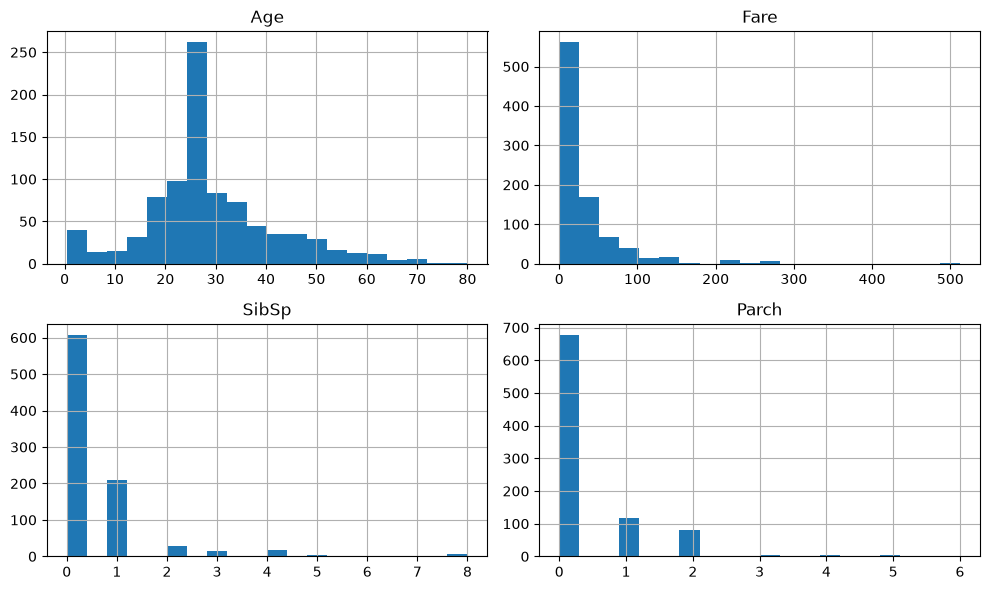

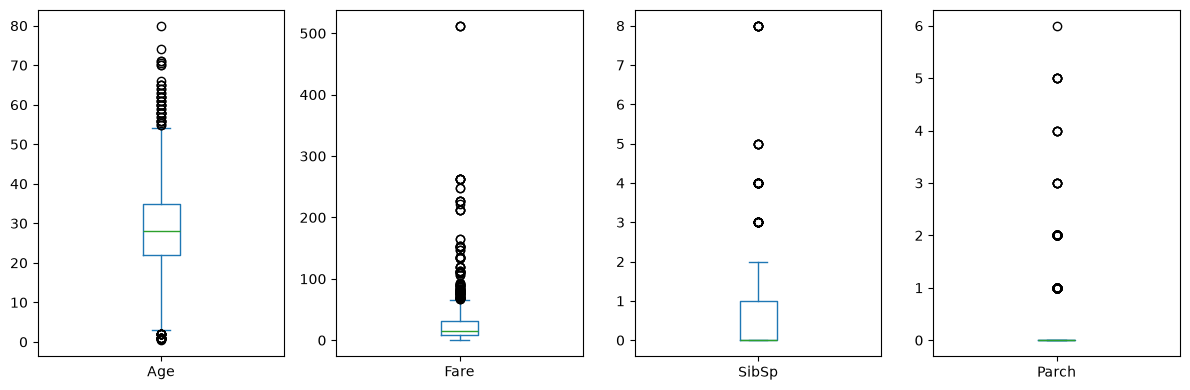


Train: (712, 8) Test: (179, 8)
     Pclass  Sex       Age  SibSp  Parch      Fare  Embarked_Q  Embarked_S
692       3    0 -0.112078      0      0  0.513812       False        True
481       2    0 -0.112078      0      0 -0.662563       False        True
527       1    0 -0.112078      0      0  3.955399       False        True
855       3    1 -0.879807      0      1 -0.467874       False        True
801       2    1  0.118241      1      1 -0.115977       False        True


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("Titanic.csv")
print("Shape:", df.shape)
print("Missing values:\n", df.isnull().sum())

# 1. Data cleaning
df = df.drop_duplicates()
df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])  # irrelevant / ~77% missing

# 2. Missing value handling
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
print("\nMissing after handling:", df.isnull().sum().sum())

# 3. Statistical analysis
print("\n", df.describe())
print("\nCorrelation with Survived:\n", df.corr(numeric_only=True)["Survived"])

# 4. Visualization (histograms and boxplots)
num = ["Age", "Fare", "SibSp", "Parch"]
df[num].hist(bins=20, figsize=(10, 6))
plt.tight_layout()
plt.show()
df[num].plot(kind="box", subplots=True, layout=(1, 4), figsize=(12, 4))
plt.tight_layout()
plt.show()

# 5. Encoding
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})            # label encoding
df = pd.get_dummies(df, columns=["Embarked"], drop_first=True)  # one-hot encoding

# 6. Train-test split (before scaling to avoid data leakage)
X, y = df.drop(columns="Survived"), df["Survived"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 7. Feature scaling (fit on train only)
cols = ["Age", "Fare"]
scaler = StandardScaler()
X_train, X_test = X_train.copy(), X_test.copy()
X_train[cols] = scaler.fit_transform(X_train[cols])
X_test[cols] = scaler.transform(X_test[cols])

print("\nTrain:", X_train.shape, "Test:", X_test.shape)
print(X_train.head())